# PERC2 load model in ANDES: verification tests

This notebook tests the ANDES implementation of the PowerWorld `PERC2` load model, `andes/models/dynload/perc2.py`. PERC2 extends PERC1 with a ramp time defined at rated power (`Tramp × Lfm`), a total current limit `Imax`, a high-voltage cease threshold, a reconnection voltage window, long-cease zones for low and high voltage, frequency thresholds after which the load never reconnects, one enable flag per zone, and data modifications at the start of a simulation.

| Test | Object | Input | Compared with |
|---|---|---|---|
| A. Logic | function `perc2_fracon_step`, the cease/reconnect state machine of the model | prescribed filtered voltage and frequency | event times derived by hand; the PowerWorld pseudo-code transcribed in this notebook |
| B. Device | the full model on an infinite bus, `perc2_inf_bus.xlsx` | prescribed terminal voltage and frequency deviation | the block diagram re-implemented in this notebook |
| C. System | a data center in the IEEE 14-bus system, `ieee14_perc2_fault.xlsx` and `ieee14_perc2_gentrip.xlsx` | bus faults, generator trip | the pseudo-code replayed on the recorded voltage and frequency |

The references of Section 1 are written from the PowerWorld documentation and share no code with the ANDES model. PowerWorld simulation results were not available, so the tests check the implementation against the documented model, not against PowerWorld output.

**Requirements.** ANDES with the `PERC2` model, NumPy, pandas, Matplotlib. Run time about half a minute.

In [1]:
%matplotlib inline
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import andes
from andes.models.dynload.perc2 import (
    TIMER_BITS,
    perc2_data_modifications,
    perc2_fracon_step,
    perc2_initial_state,
    perc2_params,
    perc2_timer_bitmask,
)

andes.config_logger(stream_level=40)  # errors only

HERE = Path.cwd()  # run the notebook from its own folder
CASE_INF = HERE / 'perc2_inf_bus.xlsx'
CASE_FAULT = HERE / 'ieee14_perc2_fault.xlsx'
CASE_TRIP = HERE / 'ieee14_perc2_gentrip.xlsx'
for _f in (CASE_INF, CASE_FAULT, CASE_TRIP):
    assert _f.exists(), f'{_f.name} not found: start the notebook from its own folder'

# generate the numerical code of PERC2 if it is missing or out of date
_probe = andes.System(default_config=True, no_output=True)
if getattr(_probe.PERC2.calls, 'md5', None) != _probe.PERC2.get_md5():
    andes.prepare(models=['PERC2'])
TTOL = _probe.PERC2.config.ttol  # tolerance of the time comparisons in the logic (1e-8 s)
del _probe

SB, FN = 100.0, 60.0  # MVA base, nominal frequency (Hz)
CHECKS = []


def check(cid, desc, ok, detail=''):
    """Record a check and print PASS / FAIL."""
    CHECKS.append(dict(id=cid, description=desc, passed=bool(ok), detail=str(detail)))
    print(f"[{'PASS' if ok else 'FAIL'}] {cid:<4} {desc}" + (f'\n            {detail}' if detail else ''))


print(f'ANDES {andes.__version__}')

ANDES 1.10.0.post114+g31ff8f76b


In [2]:
# Figure style
W2 = 7.16  # figure width (in)
FS = 8.0
C_BLUE, C_ORANGE, C_GREEN, C_MAG, C_GREY, C_INK = '#0072B2', '#D55E00', '#009E73', '#CC79A7', '0.55', '0.15'
plt.rcParams.update({
    'font.family': 'serif',
    'font.serif': ['Times New Roman', 'Nimbus Roman', 'TeX Gyre Termes', 'Liberation Serif', 'DejaVu Serif'],
    'font.size': FS, 'mathtext.fontset': 'stix',
    'axes.labelsize': FS, 'axes.titlesize': FS, 'xtick.labelsize': FS, 'ytick.labelsize': FS,
    'legend.fontsize': FS - 1, 'legend.frameon': False, 'legend.handlelength': 1.8,
    'axes.linewidth': 0.8, 'axes.grid': True, 'grid.color': '0.88', 'grid.linewidth': 0.4,
    'xtick.direction': 'in', 'ytick.direction': 'in', 'lines.linewidth': 1.3,
    'figure.dpi': 150, 'figure.facecolor': 'white',
})


def panel(ax, tag, text=''):
    ax.set_title(f'({tag})' + ('  ' + text if text else ''), loc='left', fontsize=FS, pad=3.0)

## 1 References

`data_modifications` and `CeaseLogic2` are the data modifications and the cease/reconnect pseudo-code of the help page, statement by statement. `limit_currents` is its current-limit procedure. `Perc2Reference` is the block diagram, integrated with the trapezoidal rule, the method ANDES uses, so the two can be compared down to the solver tolerance.

In [3]:
MONITOR, CEASED, RAMP = 0, 1, 2  # Mode
MODE = {MONITOR: 'Monitor', CEASED: 'Ceased', RAMP: 'Ramp'}
LEVEL = {-1: 'none', 0: 'Cease', 1: 'Long', 2: 'Never'}  # CeaseLevel and TimerDelayActiveLevel
TIMERS = ['VLcease', 'VHcease', 'LV1', 'LV2', 'LV3', 'LV4', 'HV1', 'HV2', 'HV3', 'HV4', 'LF1', 'HF1', 'Recon']

# PowerWorld default parameters of PERC2
DEFAULTS = dict(
    VLMflag=1, VHMflag=1, VLLflag=1, VHLflag=1, FLflag=1, FHflag=1,
    Lfm=0.80, QPratio=0.66, Tt=0.02, Tv=0.02, Tf=0.02, Dbdl=0.0, Dbdh=0.0, Kdroop=10.0,
    Kvp=0.02, Tvp=0.02, Kvq=0.5, Tvq=0.10, Tap=0.0, Tbp=0.0, Taq=0.0, Tbq=0.0, nP=0.0, nQ=1.0,
    Ipmax=1.0, Ipmin=0.0, Iqmax=0.66, Iqmin=-0.66, Imax=2.0,
    Fcease=1.0, Frecon=1.0, Tdelay=0.0, VLrecon=0.80, VHrecon=2.0, Tramp=0.15, Trecon=0.05,
    VLcease=0.80, VHcease=2.0, Tcease=0.01,
    TLrampL=5.0, TLreconL=0.05,
    VLC1=0.90, TVLC1=2.0, VLC2=0.80, TVLC2=0.5, VLC3=0.50, TVLC3=0.25, VLC4=0.35, TVLC4=0.15,
    TLrampH=5.0, TLreconH=0.05,
    VHC1=1.10, TVHC1=1.0, VHC2=2.0, TVHC2=99.0, VHC3=2.0, TVHC3=99.0, VHC4=2.0, TVHC4=99.0,
    FLC1=57.0, TFLC1=999.0, FHC1=63.0, TFHC1=999.0,
)


def data_modifications(prm):
    """ "Data modifications run at the beginning of a simulation" of the help page."""
    p = dict(prm)
    if p['Lfm'] < 0.001:
        p['Lfm'] = 1.0
    if p['Fcease'] > 1:
        p['Fcease'] = 1.0
    for k in ('Tramp', 'TLrampL', 'TLrampH', 'Trecon', 'TLreconL', 'TLreconH'):
        p[k] = max(p[k], 0.0)
    for k in ('VLcease', 'VLC1', 'VLC2', 'VLC3', 'VLC4'):  # VLrecon is not below any low threshold
        p['VLrecon'] = max(p['VLrecon'], p[k])
    for k in ('VHcease', 'VHC1', 'VHC2', 'VHC3', 'VHC4'):  # a non-positive high threshold is ignored
        if p[k] <= 0:
            p[k] = 999.0
    for k in ('VHcease', 'VHC1', 'VHC2', 'VHC3', 'VHC4'):  # VHrecon is not above any high threshold
        p['VHrecon'] = min(p['VHrecon'], p[k])
    if p['VHrecon'] < p['VLrecon']:
        p['VHrecon'] = 999.0
    return p


class CeaseLogic2:
    """PERC2 cease/reconnect pseudo-code for one device, statement by statement.

    Three cease levels: 0 cease zone (VLcease / VHcease, Tcease), 1 long cease (VLC1-4, VHC1-4 with their
    own timers), 2 never reconnect (frequency). A time comparison a >= b is evaluated as a >= b - ttol.
    """

    def __init__(self, prm, ttol=TTOL):
        self.p = p = data_modifications(dict(DEFAULTS, **prm))
        self.ttol = ttol
        # "Initialize the following before simulation starts"
        self.FracOn, self.Mode = 1.0, MONITOR
        self.CeaseLevel = self.TdLevel = -1  # TdLevel: TimerDelayActiveLevel
        self.TimerDelay = self.TStartRamp = 0.0
        self.TrampUsed, self.TreconUsed = p['Tramp'] * p['Lfm'], p['Trecon']
        self.active = {name: False for name in TIMERS}
        self.start = {name: 0.0 for name in TIMERS}

    def ge(self, a, b):
        return a >= b - self.ttol

    def handle(self, name, make_active, t):
        """LOCAL_HandleTimer: start the timer when the condition appears, stop it when it disappears."""
        if not make_active:
            self.active[name] = False
        elif not self.active[name]:
            self.start[name], self.active[name] = t, True

    def expired(self, name, T, t):
        return self.active[name] and self.ge(t - self.start[name], T)

    def escalate(self, level, t):
        if self.Mode == CEASED:
            self.CeaseLevel = level  # already ceased: raise the level
        else:
            if self.TdLevel < 0:  # start the delay timer only once
                self.TimerDelay = t
            self.TdLevel = level

    def gate(self, level):
        """Timers of a level are processed only while the present level is lower."""
        return (self.TdLevel if self.Mode != CEASED else self.CeaseLevel) < level

    def step(self, t, Vfilt, Ffilt):
        """Run the pseudo-code once ("at each time step")."""
        p = self.p
        if p['Fcease'] <= 0:
            return
        f_final = 1 - p['Fcease'] + p['Frecon'] * p['Fcease']
        if self.Mode == RAMP and self.TdLevel < 0:  # the ramp is frozen while the delay timer runs
            if self.ge(t, self.TStartRamp + self.TrampUsed):
                self.FracOn, self.Mode = f_final, MONITOR
                self.TrampUsed = p['Tramp'] * p['Lfm']
            else:
                self.FracOn = 1 - p['Fcease'] + p['Frecon'] * p['Fcease'] * (t - self.TStartRamp) / self.TrampUsed
        # level 2: frequency, never reconnect
        if self.gate(2):
            if p['FLflag'] != 0:
                self.handle('LF1', Ffilt < p['FLC1'], t)
            if p['FHflag'] != 0:
                self.handle('HF1', Ffilt > p['FHC1'], t)
            if (p['FLflag'] != 0 and self.expired('LF1', p['TFLC1'], t)) or (
                p['FHflag'] != 0 and self.expired('HF1', p['TFHC1'], t)
            ):
                self.TrampUsed, self.TreconUsed = 999999999.0, -1.0
                self.escalate(2, t)
        # level 1: long high-voltage zone
        if p['VHLflag'] != 0 and self.gate(1):
            for i in range(1, 5):
                self.handle(f'HV{i}', Vfilt > p[f'VHC{i}'], t)
            if any(self.expired(f'HV{i}', p[f'TVHC{i}'], t) for i in range(1, 5)):
                self.TrampUsed, self.TreconUsed = p['TLrampH'] * p['Lfm'], p['TLreconH']
                self.escalate(1, t)
        # level 1: long low-voltage zone
        if p['VLLflag'] != 0 and self.gate(1):
            for i in range(1, 5):
                self.handle(f'LV{i}', Vfilt < p[f'VLC{i}'], t)
            if any(self.expired(f'LV{i}', p[f'TVLC{i}'], t) for i in range(1, 5)):
                self.TrampUsed, self.TreconUsed = p['TLrampL'] * p['Lfm'], p['TLreconL']
                self.escalate(1, t)
        # level 0: cease zone
        if self.gate(0):
            if p['VLMflag'] != 0:
                self.handle('VLcease', Vfilt < p['VLcease'], t)
            if p['VHMflag'] != 0:
                self.handle('VHcease', Vfilt > p['VHcease'], t)
            if (p['VLMflag'] != 0 and self.expired('VLcease', p['Tcease'], t)) or (
                p['VHMflag'] != 0 and self.expired('VHcease', p['Tcease'], t)
            ):
                self.TrampUsed, self.TreconUsed = p['Tramp'] * p['Lfm'], p['Trecon']
                self.escalate(0, t)
        if self.Mode != CEASED:  # cease when the delay timer expires
            if self.TdLevel >= 0 and self.ge(t - self.TimerDelay, p['Tdelay']):
                self.CeaseLevel, self.Mode, self.FracOn, self.TdLevel = self.TdLevel, CEASED, 1 - p['Fcease'], -1
        else:  # reconnection: the voltage must stay inside [VLrecon, VHrecon] for TreconUsed
            self.handle('Recon', p['VLrecon'] <= Vfilt <= p['VHrecon'], t)
            if self.active['Recon'] and self.TreconUsed >= 0 and self.ge(t - self.start['Recon'], self.TreconUsed):
                self.active = {name: False for name in TIMERS}
                self.CeaseLevel, self.TreconUsed = -1, p['Trecon']
                if self.TrampUsed == 0:  # no ramp: jump back
                    self.Mode, self.FracOn = MONITOR, f_final
                else:
                    self.Mode, self.TStartRamp = RAMP, t

    def state(self):
        """Mode, CeaseLevel, TdLevel, active timers (bit mask), TrampUsed, TreconUsed, TStartRamp, FracOn."""
        tact = sum(2**i for i, name in enumerate(TIMERS) if self.active[name])
        return (self.Mode, self.CeaseLevel, self.TdLevel, tact, self.TrampUsed, self.TreconUsed,
                self.TStartRamp, self.FracOn)


LOGIC_FIELDS = ['Mode', 'CeaseLevel', 'TdLevel', 'Tact', 'TrampUsed', 'TreconUsed', 'TStartRamp', 'FracOn']

In [4]:
def limit_currents(Pctrl, Qctrl, Vfilt, Vinit, p):
    """CalculateIpvIqv of the help page: voltage exponent, power -> current, then the limits.
    Ip is limited first; Iq gets the current that Imax leaves. Returns Ipv, Iqv and the unlimited values."""
    Ipv = Pctrl * (Vfilt / Vinit) ** p['nP']
    Iqv = Qctrl * (Vfilt / Vinit) ** p['nQ']
    div = Vfilt if Vfilt > 0.001 else 0.001
    Ipv, Iqv = Ipv / div, Iqv / div
    Ipcmd, Iqcmd = Ipv, Iqv
    Ipmax, Ipmin, Iqmax, Iqmin, Imax = p['Ipmax'], p['Ipmin'], p['Iqmax'], p['Iqmin'], p['Imax']
    if Imax > 0:
        Ipmax, Ipmin = min(Ipmax, Imax), max(Ipmin, -Imax)
    if Ipv > Ipmax:
        Ipv = Ipmax
    if Ipv < Ipmin:
        Ipv = Ipmin
    if Imax > 0:
        left = Imax**2 - Ipv**2
        if left < 1e-12:  # no current left for Iq
            Iqmax = Iqmin = 0.0
        else:
            Iqmax, Iqmin = min(Iqmax, left**0.5), max(Iqmin, -(left**0.5))
    if Iqv > Iqmax:
        Iqv = Iqmax
    if Iqv < Iqmin:
        Iqv = Iqmin
    return Ipv, Iqv, Ipcmd, Iqcmd


class Perc2Reference:
    """PERC2 block diagram driven by a prescribed terminal voltage V(t) and frequency deviation dw(t).

    Per-unit values are on MBase = MWinit / Lfm. Host rules: Tt >= 4 x time step; frequency input ignored
    below 0.7 pu; constant impedance if V0 < VLcease, V0 < 0.5 pu or MWinit <= 0.
    """

    def __init__(self, prm, V0, P0, Q0, h):
        self.raw = dict(DEFAULTS, **prm)
        self.p = p = data_modifications(self.raw)
        self.V0, self.P0, self.Q0 = V0, P0, Q0
        self.fallback = V0 < p['VLcease'] or V0 < 0.5 or P0 <= 0
        self.MBase = 0.0 if self.fallback else P0 / p['Lfm']
        self.Pinit = 0.0 if self.fallback else p['Lfm']  # MWinit / MBase
        self.Qinit = 0.0 if self.fallback else p['QPratio'] * p['Lfm']  # MvarInit = QPratio x MWinit
        # stand-alone model: the rest of the initial Mvar is a constant current added after the limiter
        self.Iqextra = 0.0 if self.fallback else (Q0 - p['QPratio'] * P0) / (self.MBase * V0)
        self.Tt = p['Tt'] if p['Tt'] >= 4 * h * (1 - 5e-4) else 4 * h

    def algebraic(self, x, V):
        """All block outputs for the state vector x and the terminal voltage."""
        p = self.p
        xPc, xQc, xdP, xdQ, wfilt, Vfilt, Ip, Iq = x
        dP = p['Kvp'] * (V - xdP) / p['Tvp'] if p['Tvp'] > 0 else 0.0  # washouts on the raw voltage
        dQ = p['Kvq'] * (V - xdQ) / p['Tvq'] if p['Tvq'] > 0 else 0.0
        db = wfilt - p['Dbdh'] if wfilt > p['Dbdh'] else (wfilt - p['Dbdl'] if wfilt < p['Dbdl'] else 0.0)
        Pin = self.Pinit + dP + p['Kdroop'] * db
        Qin = self.Qinit + dQ
        Pctrl = xPc + p['Tap'] / p['Tbp'] * (Pin - xPc) if p['Tbp'] > 0 else Pin  # lead-lags
        Qctrl = xQc + p['Taq'] / p['Tbq'] * (Qin - xQc) if p['Tbq'] > 0 else Qin
        Ipv, Iqv, Ipcmd, Iqcmd = limit_currents(Pctrl, Qctrl, Vfilt, self.V0, p)
        if self.fallback:
            Pmw, Qmvar = self.P0 * (V / self.V0) ** 2, self.Q0 * (V / self.V0) ** 2
        else:
            Pmw, Qmvar = self.MBase * V * Ip, self.MBase * V * Iq
        return dict(Vfilt=Vfilt, wfilt=wfilt, dP=dP, dQ=dQ, Pin=Pin, Qin=Qin, Pctrl=Pctrl, Qctrl=Qctrl,
                    Ipcmd=Ipcmd, Iqcmd=Iqcmd, Ipv=Ipv, Iqv=Iqv, Ip=Ip, Iq=Iq, Pmw=Pmw, Qmvar=Qmvar)

    def rhs(self, x, V, dw, FracOn):
        """Time derivatives of the eight states (zero for bypassed blocks)."""
        p, s = self.p, self.algebraic(x, V)
        xPc, xQc, xdP, xdQ, wfilt, Vfilt, Ip, Iq = x
        dx = np.zeros(8)
        if p['Tbp'] > 0:
            dx[0] = (s['Pin'] - xPc) / p['Tbp']
        if p['Tbq'] > 0:
            dx[1] = (s['Qin'] - xQc) / p['Tbq']
        if p['Tvp'] > 0:
            dx[2] = (V - xdP) / p['Tvp']
        if p['Tvq'] > 0:
            dx[3] = (V - xdQ) / p['Tvq']
        dx[4] = ((dw if V >= 0.7 else 0.0) - wfilt) / p['Tf']
        dx[5] = (V - Vfilt) / p['Tv']
        dx[6] = (FracOn * s['Ipv'] - Ip) / self.Tt  # output lags, FracOn multiplies their inputs
        dx[7] = (FracOn * (s['Iqv'] + self.Iqextra) - Iq) / self.Tt
        return dx

    def trap_step(self, x0, f0, h, V1, dw1, FracOn):
        """One step of the implicit trapezoidal rule (Newton, numerical Jacobian)."""
        x = x0 + h * f0
        for _ in range(50):
            f1 = self.rhs(x, V1, dw1, FracOn)
            G = x - x0 - 0.5 * h * (f0 + f1)
            J = np.eye(8)
            for j in range(8):
                xp = x.copy()
                d = 1e-7 * max(1.0, abs(x[j]))
                xp[j] += d
                J[:, j] -= 0.5 * h * (self.rhs(xp, V1, dw1, FracOn) - f1) / d
            dx = np.linalg.solve(J, -G)
            x = x + dx
            if np.max(np.abs(dx)) < 1e-13:
                break
        return x

    def simulate(self, t, V, dw):
        """Integrate on the grid t with the inputs V, dw given on the grid; the logic runs once per point
        with Vfilt and Ffilt = 60 (1 + wfilt), and the new FracOn is held during the following step."""
        logic = CeaseLogic2(self.raw)
        x = np.array([self.Pinit, self.Qinit, self.V0, self.V0, 0.0, self.V0, 0.0, 0.0])
        s0 = self.algebraic(x, self.V0)
        x[6], x[7] = s0['Ipv'], s0['Iqv'] + self.Iqextra
        keys = list(s0) + LOGIC_FIELDS
        out = {k: np.zeros(len(t)) for k in keys}
        for n in range(len(t)):
            if not self.fallback:
                logic.step(t[n], x[5], FN * (1 + x[4]))
            s = self.algebraic(x, V[n])
            s.update(zip(LOGIC_FIELDS, logic.state()))
            for k in keys:
                out[k][n] = s[k]
            if n < len(t) - 1:
                f0 = self.rhs(x, V[n], dw[n], logic.FracOn)
                x = self.trap_step(x, f0, t[n + 1] - t[n], V[n + 1], dw[n + 1], logic.FracOn)
        return out

## 2 Test A: cease/reconnect logic

The model function and `CeaseLogic2` receive the same samples of the filtered voltage and frequency (step 1 ms). `Fcease` = 0.75 and `Frecon` = 0.60 as in the PowerWorld FracOn example, so `FracOn` goes 1.00 → 0.25 → 0.70. `Tramp` = 1.25 s with `Lfm` = 0.8 gives a 1.0 s ramp.

| Zone | Thresholds and timers | Return |
|---|---|---|
| cease (level 0) | `VLcease` 0.80, `VHcease` 1.20 pu, `Tcease` 0.10 s, `Tdelay` 0.05 s | `Trecon` 0.20 s, ramp 1.0 s |
| long low (level 1) | `VLC1–4` 0.90 / 0.80 / 0.50 / 0.35 pu for 2.0 / 1.0 / 0.25 / 0.15 s | `TLreconL` 0.5 s, ramp 2.0 s |
| long high (level 1) | `VHC1` 1.10 pu for 1.0 s | `TLreconH` 0.5 s, ramp 2.0 s |
| frequency (level 2) | `FLC1` 59 Hz, `FHC1` 61 Hz for 0.5 s | never |

Reconnection window: 0.90–1.10 pu.

| Scenario | Prescribed input | Expected |
|---|---|---|
| A1 | 0.70 pu during 1.0–1.5 s and 4.0–4.5 s; 0.75 pu for 50 ms | as the PERC1 FracOn example: cease at 1.15 s, ramp 1.70–2.70 s |
| A2 | 1.30 pu during 1.0–1.5 s; 1.25 pu for 50 ms | cease by `VHcease` |
| A3 | after a cease: 0.85 pu, then 1.15 pu, then 1.00 pu | the reconnection timer starts only inside the window, at 2.3 s |
| A4 | 0.85 pu during 1–4 s | no level-0 cease; `VLC1` expires at 3.0 s, long-cease return times |
| A5 | 0.70 pu during 1.0–2.5 s | level-0 cease at 1.15 s, raised to level 1 at 2.0 s by `VLC2` while ceased |
| A6 | 1.15 pu during 1–3 s | `VHC1` expires at 2.0 s, long-cease return times |
| A7 | 58.5 Hz during 1–2 s | cease at 1.55 s, no reconnection after the frequency recovers |
| A8 | 0.70 pu during 1.0–2.5 s and 61.5 Hz during 1.2–1.8 s | level 0 raised to level 2 while ceased, no reconnection |
| A9 | second dip at 2.0 s, during the ramp | `FracOn` frozen during `Tdelay`, then 0.25 again |
| A10–A12 | | ramp time for three values of `Lfm`; enable flags; data modifications |
| A13 | 200 random parameter sets, flags and profiles | model function equal to the pseudo-code at every step |

In [5]:
# test parameters: fractions of the PowerWorld FracOn example, TrampUsed = Tramp x Lfm = 1.0 s
PRM = dict(
    Fcease=0.75, Frecon=0.60, Lfm=0.80, Tramp=1.25, Trecon=0.20, Tcease=0.10, Tdelay=0.05,
    VLcease=0.80, VHcease=1.20, VLrecon=0.90, VHrecon=1.10,
    VLC1=0.90, TVLC1=2.0, VLC2=0.80, TVLC2=1.0, VLC3=0.50, TVLC3=0.25, VLC4=0.35, TVLC4=0.15,
    TLreconL=0.5, TLrampL=2.5,
    VHC1=1.10, TVHC1=1.0, VHC2=2.0, TVHC2=99.0, VHC3=2.0, TVHC3=99.0, VHC4=2.0, TVHC4=99.0,
    TLreconH=0.5, TLrampH=2.5,
    FLC1=59.0, TFLC1=0.5, FHC1=61.0, TFHC1=0.5,
)
FLAGS = ('VLMflag', 'VHMflag', 'VLLflag', 'VHLflag', 'FLflag', 'FHflag')  # one enable flag per zone
F_CEASED, F_FINAL = 0.25, 0.70
H_LOGIC = 0.001  # sampling step (s)
assert list(TIMER_BITS) == TIMERS  # bit order of the model output Tact


def piecewise(segments, t):
    """Right-continuous piecewise-constant signal: segments = [(start time, value), ...]."""
    starts = np.array([s for s, _ in segments])
    values = np.array([v for _, v in segments])
    return values[np.searchsorted(starts, t + 1e-9, side='right') - 1]


def run_logic(prm, t, v, f):
    """Drive the model function and the reference with the same Vfilt, Ffilt samples.
    Returns two arrays (n, 8) with the columns LOGIC_FIELDS."""
    st, ref = perc2_initial_state(1), CeaseLogic2(prm)
    st = st._replace(trampu=np.array([ref.TrampUsed]), treconu=np.array([ref.TreconUsed]))  # as the model initializes
    P = perc2_params(1, **prm)  # model parameters after its own data modifications
    M, R = np.zeros((len(t), 8)), np.zeros((len(t), 8))
    for k in range(len(t)):
        if k > 0:  # the logic runs once per step, after t = 0
            st = perc2_fracon_step(st, t[k], v[k : k + 1], f[k : k + 1], P, ttol=TTOL)
            ref.step(t[k], v[k], f[k])
        M[k] = (st.mode[0], st.cl[0], st.tdl[0], perc2_timer_bitmask(st)[0], st.trampu[0], st.treconu[0],
                st.tsr[0], st.fon[0])
        R[k] = ref.state()
    return M, R


def transitions(t, S):
    """Changes of the logic outputs as (time, variable, new value)."""
    ev = []
    for k in range(1, len(t)):
        tk, a, b = round(float(t[k]), 6), S[k - 1], S[k]
        if a[0] != b[0]:
            ev.append((tk, 'Mode', MODE[int(b[0])]))
        if a[1] != b[1]:
            ev.append((tk, 'CeaseLevel', LEVEL[int(b[1])]))
        if a[2] != b[2]:
            ev.append((tk, 'TdLevel', LEVEL[int(b[2])]))
        for i, name in enumerate(TIMERS):
            if (int(a[3]) >> i) & 1 != (int(b[3]) >> i) & 1:
                ev.append((tk, name, 'on' if (int(b[3]) >> i) & 1 else 'off'))
        if a[4] != b[4]:
            ev.append((tk, 'TrampUsed', f'{b[4]:g}'))
        if a[5] != b[5]:
            ev.append((tk, 'TreconUsed', f'{b[5]:g}'))
    return ev


# scenario: Vfilt (and Ffilt) segments, expected events (time, variable, new value), final FracOn, highest CeaseLevel
SCEN_A = {
    'A1': dict(
        title='FracOn example: TrampUsed = Tramp x Lfm',
        V=[(0, 1.0), (1.0, 0.70), (1.5, 1.0), (3.0, 0.75), (3.05, 1.0), (4.0, 0.70), (4.5, 1.0)], tf=7.0,
        expected=[(1.000, 'VLcease', 'on'), (1.100, 'TdLevel', 'Cease'), (1.150, 'Mode', 'Ceased'),
                  (1.500, 'Recon', 'on'), (1.700, 'Mode', 'Ramp'), (2.700, 'Mode', 'Monitor'),
                  (3.000, 'VLcease', 'on'), (3.050, 'VLcease', 'off'),
                  (4.100, 'TdLevel', 'Cease'), (4.150, 'Mode', 'Ceased'), (4.700, 'Mode', 'Ramp'),
                  (5.700, 'Mode', 'Monitor')],
        final=F_FINAL, level=0,
    ),
    'A2': dict(
        title='high-voltage cease: 1.30 pu > VHcease',
        V=[(0, 1.0), (1.0, 1.30), (1.5, 1.0), (3.0, 1.25), (3.05, 1.0)], tf=4.0,
        expected=[(1.000, 'VHcease', 'on'), (1.000, 'HV1', 'on'), (1.100, 'TdLevel', 'Cease'),
                  (1.150, 'Mode', 'Ceased'), (1.500, 'HV1', 'off'), (1.500, 'Recon', 'on'),
                  (1.700, 'Mode', 'Ramp'), (2.700, 'Mode', 'Monitor'),
                  (3.000, 'VHcease', 'on'), (3.050, 'VHcease', 'off')],
        final=F_FINAL, level=0,
    ),
    'A3': dict(
        title='reconnection window: [VLrecon, VHrecon] = [0.90, 1.10]',
        V=[(0, 1.0), (1.0, 0.70), (1.5, 0.85), (1.8, 1.15), (2.3, 1.0)], tf=4.0,
        expected=[(1.150, 'Mode', 'Ceased'), (1.500, 'LV2', 'off'), (1.800, 'LV1', 'off'), (1.800, 'HV1', 'on'),
                  (2.300, 'HV1', 'off'), (2.300, 'Recon', 'on'), (2.500, 'Mode', 'Ramp'), (3.500, 'Mode', 'Monitor')],
        final=F_FINAL, level=0,
    ),
    'A4': dict(
        title='long low voltage: 0.85 pu for 3 s (VLC1 0.90 / 2 s)',
        V=[(0, 1.0), (1.0, 0.85), (4.0, 1.0)], tf=7.0,
        expected=[(1.000, 'LV1', 'on'), (3.000, 'TdLevel', 'Long'), (3.000, 'TrampUsed', '2'),
                  (3.000, 'TreconUsed', '0.5'), (3.050, 'Mode', 'Ceased'), (3.050, 'CeaseLevel', 'Long'),
                  (4.000, 'Recon', 'on'), (4.500, 'Mode', 'Ramp'), (6.500, 'Mode', 'Monitor')],
        final=F_FINAL, level=1,
    ),
    'A5': dict(
        title='level raised while ceased: 0.70 pu for 1.5 s (VLC2 0.80 / 1 s)',
        V=[(0, 1.0), (1.0, 0.70), (2.5, 1.0)], tf=6.0,
        expected=[(1.150, 'Mode', 'Ceased'), (2.000, 'CeaseLevel', 'Long'), (2.000, 'TrampUsed', '2'),
                  (2.000, 'TreconUsed', '0.5'), (2.500, 'Recon', 'on'), (3.000, 'Mode', 'Ramp'),
                  (5.000, 'Mode', 'Monitor')],
        final=F_FINAL, level=1,
    ),
    'A6': dict(
        title='long high voltage: 1.15 pu for 2 s (VHC1 1.10 / 1 s)',
        V=[(0, 1.0), (1.0, 1.15), (3.0, 1.0)], tf=6.0,
        expected=[(1.000, 'HV1', 'on'), (2.000, 'TdLevel', 'Long'), (2.000, 'TrampUsed', '2'),
                  (2.000, 'TreconUsed', '0.5'), (2.050, 'Mode', 'Ceased'), (3.000, 'Recon', 'on'),
                  (3.500, 'Mode', 'Ramp'), (5.500, 'Mode', 'Monitor')],
        final=F_FINAL, level=1,
    ),
    'A7': dict(
        title='low frequency: 58.5 Hz for 1 s (FLC1 59 Hz / 0.5 s), never reconnects',
        V=[(0, 1.0)], F=[(0, 60.0), (1.0, 58.5), (2.0, 60.0)], tf=5.0,
        expected=[(1.000, 'LF1', 'on'), (1.500, 'TdLevel', 'Never'), (1.500, 'TrampUsed', '1e+09'),
                  (1.500, 'TreconUsed', '-1'), (1.550, 'Mode', 'Ceased'), (1.550, 'CeaseLevel', 'Never'),
                  (1.551, 'Recon', 'on')],
        final=F_CEASED, level=2,
    ),
    'A8': dict(
        title='frequency while ceased: level 0 raised to never reconnect',
        V=[(0, 1.0), (1.0, 0.70), (2.5, 1.0)], F=[(0, 60.0), (1.2, 61.5), (1.8, 60.0)], tf=5.0,
        expected=[(1.150, 'Mode', 'Ceased'), (1.200, 'HF1', 'on'), (1.700, 'CeaseLevel', 'Never'),
                  (1.700, 'TreconUsed', '-1'), (2.500, 'Recon', 'on')],
        final=F_CEASED, level=2,
    ),
    'A9': dict(
        title='dip during the ramp: FracOn frozen during Tdelay, then ceased again',
        V=[(0, 1.0), (1.0, 0.70), (1.5, 1.0), (2.0, 0.70), (2.12, 0.85), (2.3, 1.0)], tf=5.0,
        expected=[(1.700, 'Mode', 'Ramp'), (2.000, 'VLcease', 'on'), (2.100, 'TdLevel', 'Cease'),
                  (2.150, 'Mode', 'Ceased'), (2.300, 'Recon', 'on'), (2.500, 'Mode', 'Ramp'),
                  (3.500, 'Mode', 'Monitor')],
        final=F_FINAL, level=0,
    ),
}


def run_scenario(sc, prm=PRM):
    t = np.arange(int(round(sc['tf'] / H_LOGIC)) + 1) * H_LOGIC
    v, f = piecewise(sc['V'], t), piecewise(sc.get('F', [(0, FN)]), t)
    M, R = run_logic(prm, t, v, f)
    return dict(t=t, v=v, f=f, M=M, R=R)


RES_A = {}
for key, sc in SCEN_A.items():
    r = RES_A[key] = run_scenario(sc)
    M, R = r['M'], r['R']
    ev = transitions(r['t'], M)
    missing = [e for e in sc['expected'] if e not in ev]
    same = np.array_equal(M[:, :6], R[:, :6]) and np.abs(M[:, 6:] - R[:, 6:]).max() < 1e-12
    check(
        key,
        sc['title'],
        same and not missing and abs(M[-1, 7] - sc['final']) < 1e-12 and M[:, 1].max() == sc['level'],
        f"{len(sc['expected'])} expected events found, every step equal to the reference, final FracOn "
        f"{M[-1, 7]:.2f}, highest CeaseLevel {M[:, 1].max():.0f}",
    )

[PASS] A1   FracOn example: TrampUsed = Tramp x Lfm
            12 expected events found, every step equal to the reference, final FracOn 0.70, highest CeaseLevel 0
[PASS] A2   high-voltage cease: 1.30 pu > VHcease
            10 expected events found, every step equal to the reference, final FracOn 0.70, highest CeaseLevel 0
[PASS] A3   reconnection window: [VLrecon, VHrecon] = [0.90, 1.10]
            8 expected events found, every step equal to the reference, final FracOn 0.70, highest CeaseLevel 0
[PASS] A4   long low voltage: 0.85 pu for 3 s (VLC1 0.90 / 2 s)
            9 expected events found, every step equal to the reference, final FracOn 0.70, highest CeaseLevel 1
[PASS] A5   level raised while ceased: 0.70 pu for 1.5 s (VLC2 0.80 / 1 s)
            7 expected events found, every step equal to the reference, final FracOn 0.70, highest CeaseLevel 1
[PASS] A6   long high voltage: 1.15 pu for 2 s (VHC1 1.10 / 1 s)
            8 expected events found, every step equal to the refe

In [6]:
# ramp time scales with the loading factor: TrampUsed = Tramp x Lfm
dip = dict(V=[(0, 1.0), (1.0, 0.70), (1.5, 1.0)], tf=4.0)
dur = {}
for lfm in (0.4, 0.8, 1.0):
    M = run_scenario(dip, dict(PRM, Lfm=lfm))['M']
    dur[lfm] = np.count_nonzero(M[:, 0] == RAMP) * H_LOGIC
check(
    'A10',
    'ramp duration = Tramp x Lfm for Lfm = 0.4 / 0.8 / 1.0',
    all(abs(dur[x] - PRM['Tramp'] * x) < 1e-9 for x in dur),
    ' / '.join(f'{v:.3f} s' for v in dur.values()),
)

# each flag switches its zone off
off = {}
for key, flag in (('A1', 'VLMflag'), ('A2', 'VHMflag'), ('A4', 'VLLflag'), ('A6', 'VHLflag'), ('A7', 'FLflag')):
    off[flag] = run_scenario(SCEN_A[key], dict(PRM, **{flag: 0}))['M'][:, 7].min()
check(
    'A11',
    'a zone whose flag is 0 does not cease the load',
    all(v == 1.0 for v in off.values()),
    'FracOn stays 1 with ' + ', '.join(off) + ' = 0',
)

# data modifications
d = data_modifications(DEFAULTS)
m = perc2_data_modifications({key: np.array([float(val)]) for key, val in DEFAULTS.items()})
cases = dict(VHcease=0.0, VHrecon=0.5, Lfm=0.0, Fcease=1.5, Tramp=-1.0)
ok = d['VLrecon'] == 0.90 and d['VHrecon'] == 1.10 and m['VLrecon'][0] == 0.90 and m['VHrecon'][0] == 1.10
for key, val in cases.items():
    raw = dict(DEFAULTS, **{key: val})
    d = data_modifications(raw)
    m = perc2_data_modifications({x: np.array([float(y)]) for x, y in raw.items()})
    ok = ok and all(m[x][0] == d[x] for x in d)
check(
    'A12',
    'data modifications at the start: model function equal to the documented rules',
    ok,
    'defaults give the window [0.90, 1.10]; VHcease <= 0 and VHrecon < VLrecon are ignored (999); '
    'Lfm < 0.001 -> 1; Fcease > 1 -> 1; negative times -> 0',
)

[PASS] A10  ramp duration = Tramp x Lfm for Lfm = 0.4 / 0.8 / 1.0
            0.500 s / 1.000 s / 1.250 s
[PASS] A11  a zone whose flag is 0 does not cease the load
            FracOn stays 1 with VLMflag, VHMflag, VLLflag, VHLflag, FLflag = 0
[PASS] A12  data modifications at the start: model function equal to the documented rules
            defaults give the window [0.90, 1.10]; VHcease <= 0 and VHrecon < VLrecon are ignored (999); Lfm < 0.001 -> 1; Fcease > 1 -> 1; negative times -> 0


In [7]:
# A13: random parameters, flags and voltage / frequency profiles, all devices in one vectorized call
rng = np.random.default_rng(2)
N, H_RND, T_RND = 200, 0.01, 15.0
t = np.arange(int(round(T_RND / H_RND)) + 1) * H_RND
RP = {key: (rng.random(N) < 0.8).astype(float) for key in FLAGS}  # the logic parameters of every device
RP.update(
    Fcease=np.where(rng.random(N) < 0.1, 0.0, rng.uniform(0.05, 1.2, N)), Frecon=rng.uniform(0.0, 1.5, N),
    Lfm=rng.uniform(0.3, 1.0, N), Tdelay=np.where(rng.random(N) < 0.3, 0.0, rng.uniform(0.0, 0.3, N)),
    Tcease=rng.uniform(0.0, 0.3, N), Trecon=rng.uniform(0.0, 0.5, N),
    Tramp=np.where(rng.random(N) < 0.2, 0.0, rng.uniform(0.05, 2.0, N)),
    TLrampL=rng.uniform(0.0, 3.0, N), TLrampH=rng.uniform(0.0, 3.0, N),
    TLreconL=rng.uniform(0.0, 1.0, N), TLreconH=rng.uniform(0.0, 1.0, N),
    VLcease=rng.uniform(0.5, 0.9, N), VHcease=rng.uniform(1.1, 1.3, N),
    VLrecon=rng.uniform(0.6, 1.0, N), VHrecon=rng.uniform(1.0, 1.3, N),
    FLC1=rng.uniform(59.0, 59.6, N), TFLC1=rng.uniform(0.5, 3.0, N),
    FHC1=rng.uniform(60.4, 61.0, N), TFHC1=rng.uniform(0.5, 3.0, N),
)
for i in range(1, 5):
    RP[f'VLC{i}'], RP[f'TVLC{i}'] = rng.uniform(0.3, 0.95, N), rng.uniform(0.1, 3.0, N)
    RP[f'VHC{i}'], RP[f'TVHC{i}'] = rng.uniform(1.05, 1.4, N), rng.uniform(0.1, 3.0, N)


def random_profile(lo, hi, first):
    out = np.empty((len(t), N))
    for j in range(N):  # random levels held for random times
        starts = np.cumsum(rng.uniform(0.05, 1.5, 40))
        out[:, j] = piecewise(list(zip(np.r_[0.0, starts], np.r_[first, rng.uniform(lo, hi, 40)])), t)
    return out


V, F = random_profile(0.2, 1.4, 1.0), random_profile(59.2, 60.8, 60.0)
P = perc2_params(N, **RP)
st = perc2_initial_state(N)
st = st._replace(trampu=P.Tramp * P.Lfm, treconu=P.Trecon.copy())
OUT = np.zeros((len(t), N, 4))  # Mode, CeaseLevel, Tact, FracOn
OUT[0, :, 0], OUT[0, :, 1], OUT[0, :, 3] = st.mode, st.cl, st.fon
for i in range(1, len(t)):
    st = perc2_fracon_step(st, t[i], V[i], F[i], P, ttol=TTOL)
    OUT[i] = np.column_stack([st.mode, st.cl, perc2_timer_bitmask(st), st.fon])
err, levels, n_back = 0.0, np.zeros(3, dtype=int), 0
for j in range(N):
    ref = CeaseLogic2({key: val[j] for key, val in RP.items()})
    top = -1
    for i in range(1, len(t)):
        ref.step(t[i], V[i, j], F[i, j])
        s = ref.state()
        err = max(err, abs(s[0] - OUT[i, j, 0]), abs(s[1] - OUT[i, j, 1]), abs(s[3] - OUT[i, j, 2]),
                  abs(s[7] - OUT[i, j, 3]))
        top = max(top, s[1])
    if top >= 0:
        levels[int(top)] += 1
    n_back += int(np.any(np.diff(OUT[:, j, 0]) == RAMP - CEASED) or np.any(np.diff(OUT[:, j, 0]) == MONITOR - CEASED))
check(
    'A13',
    f'{N} random parameter sets and profiles: model function equals the reference at every step',
    err < 1e-12,
    f'max difference {err:.1e}; highest level reached: cease {levels[0]}, long {levels[1]}, never {levels[2]} devices; '
    f'{n_back} devices reconnected at least once',
)

[PASS] A13  200 random parameter sets and profiles: model function equals the reference at every step
            max difference 0.0e+00; highest level reached: cease 9, long 131, never 40 devices; 180 devices reconnected at least once


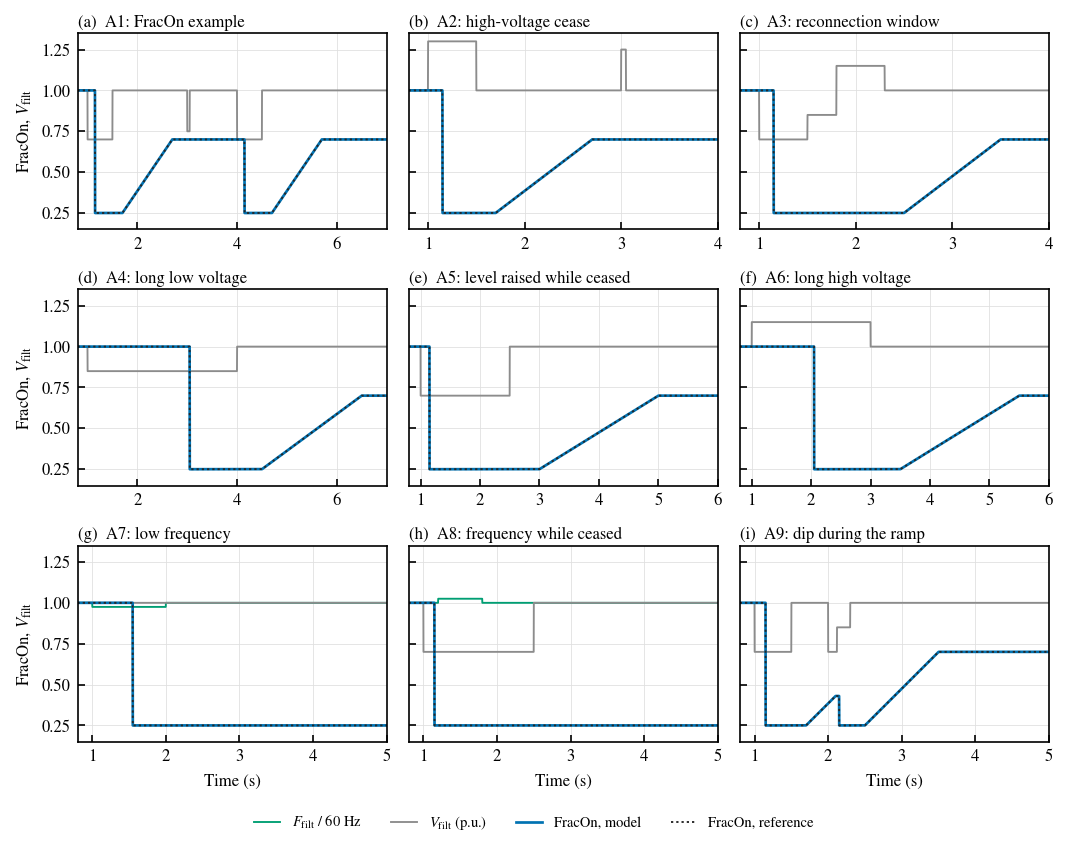

Fig. 1.  Logic level. Prescribed filtered voltage (grey) and frequency (green, panels g and h), FracOn of the model function (blue) and of the reference (dotted).


In [8]:
# Fig. 1: FracOn of the nine scenarios, model function and reference
fig, axs = plt.subplots(3, 3, figsize=(W2, 5.6), sharey=True)
for ax, (key, sc), tag in zip(axs.ravel(), SCEN_A.items(), 'abcdefghi'):
    r = RES_A[key]
    if 'F' in sc:
        ax.plot(r['t'], r['f'] / FN, color=C_GREEN, lw=0.9, label='$F_\\mathrm{filt}$ / 60 Hz')
    ax.plot(r['t'], r['v'], color=C_GREY, lw=0.9, label='$V_\\mathrm{filt}$ (p.u.)')
    ax.plot(r['t'], r['M'][:, 7], color=C_BLUE, label='FracOn, model')
    ax.plot(r['t'], r['R'][:, 7], color=C_INK, lw=0.9, ls=(0, (1.2, 1.6)), label='FracOn, reference')
    ax.set_xlim(0.8, r['t'][-1])
    ax.set_ylim(0.15, 1.35)
    panel(ax, tag, f'{key}: {sc["title"].split(":")[0]}')
for ax in axs[2]:
    ax.set_xlabel('Time (s)')
for ax in axs[:, 0]:
    ax.set_ylabel('FracOn, $V_\\mathrm{filt}$')
h, lab = axs[2, 0].get_legend_handles_labels()
fig.legend(h, lab, loc='lower center', ncol=4, bbox_to_anchor=(0.5, -0.01))
plt.tight_layout(rect=(0, 0.035, 1, 1))
plt.show()
print('Fig. 1.  Logic level. Prescribed filtered voltage (grey) and frequency (green, panels g and h), FracOn of '
      'the model function (blue) and of the reference (dotted).')

## 3 Test B: device on an infinite bus

`perc2_inf_bus.xlsx` has a load on the slack bus, replaced by PERC2. Before every step the slack voltage and the external frequency deviation `dwext` of the model are set to prescribed values, so the model sees a known $V(t)$ and $\Delta\omega(t)$. The reference runs on the same time grid (step 1/120 s) with the recorded terminal voltage.

Tolerances: 1e-7 pu on the model base for the block outputs, 1e-5 MW for $P$ and $Q$, identical logic outputs (`Mode`, `CeaseLevel`, active timers, `TrampUsed`, `TreconUsed`, `FracOn`).

In [9]:
CONT = ['Vfilt', 'wfilt', 'dP', 'dQ', 'Pin', 'Qin', 'Pctrl', 'Qctrl', 'Ipcmd', 'Iqcmd', 'Ipv', 'Iqv', 'Ip', 'Iq']
OUTPUTS = CONT + ['Pmw', 'Qmvar', 'FracOn', 'Mode', 'CeaseLevel', 'TdLevel', 'Tact', 'TrampUsed', 'TreconUsed']
H_DEV = 1 / 120  # half a cycle


def run_device(prm, V, dw=None, tf=3.0, V0=1.0, P0=50.0, Q0=20.0):
    """PERC2 on the infinite bus with prescribed V(t) and dw(t) (functions of time). Returns (system, signals)."""
    ss = andes.load(str(CASE_INF), setup=False, no_output=True, default_config=True)
    ss.Bus.v0.v[:] = [V0] * ss.Bus.n  # parameters are plain lists before setup()
    ss.Slack.v0.v[0] = V0
    ss.PQ.p0.v[0] = ss.Slack.p0.v[0] = P0 / SB
    ss.PQ.q0.v[0] = ss.Slack.q0.v[0] = Q0 / SB
    for key, val in prm.items():
        ss.PERC2.__dict__[key].v[0] = val
    ss.setup()
    ss.PFlow.config.tol = 1e-12
    ss.PFlow.run()
    ss.TDS.config.tstep, ss.TDS.config.tf, ss.TDS.config.tol = H_DEV, tf, 1e-9
    ss.TDS.config.honest, ss.TDS.config.no_tqdm = 1, 1

    def set_inputs(t, system):  # called by TDS before every step
        system.Slack.v0.v[:] = V(float(t))
        if dw is not None:
            system.PERC2.dwext.v[:] = dw(float(t))

    ss.TDS.callpert = set_inputs
    ss.TDS.run(no_summary=True)
    ss.dae.ts.unpack()
    m, ts = ss.PERC2, ss.dae.ts
    sig = dict(t=np.array(ts.t), V=np.array(ts.y[:, m.v.a[0]]))
    for key in OUTPUTS:
        var = m.__dict__[key]
        sig[key] = np.array((ts.x if var.v_code == 'x' else ts.y)[:, var.a[0]])
    return ss, sig


def reference_for(ss, sig, prm, dw=None):
    """The reference on the ANDES time grid, driven by the recorded terminal voltage."""
    m = ss.PERC2
    ref = Perc2Reference(prm, float(m.v0.v[0]), float(m.p0.v[0]) * SB, float(m.q0.v[0]) * SB, H_DEV)
    dw_t = np.zeros_like(sig['t']) if dw is None else np.array([dw(x) for x in sig['t']])
    return ref.simulate(sig['t'], sig['V'], dw_t)


def steps(*pairs, v0=1.0):
    """Signal that starts at v0 and takes the given values from the given times on."""
    return lambda t: ([v0] + [val for ts, val in pairs if t >= ts - 1e-9])[-1]

In [10]:
# B1: initialization. The PQ load is taken over at its power-flow values; data modifications are applied.
PRM_B1 = dict(QPratio=0.3, Lfm=0.7)
ss, a = run_device(PRM_B1, steps(v0=0.97), tf=0.5, V0=0.97, P0=80.0, Q0=30.0)
m = ss.PERC2
MB = 80.0 / 0.7
exp = dict(Pmw=80.0, Qmvar=30.0, MBase=MB, Ip=0.7 / 0.97, Iqextra=(30.0 - 0.3 * 80.0) / (MB * 0.97),
           VLrecon=0.90, VHrecon=1.10, TrampUsed=0.15 * 0.7)
got = dict(Pmw=a['Pmw'][0], Qmvar=a['Qmvar'][0], MBase=m.MB.v[0], Ip=a['Ip'][0], Iqextra=m.Iqx.v[0],
           VLrecon=m.VLrecone.v[0], VHrecon=m.VHrecone.v[0], TrampUsed=a['TrampUsed'][0])
print(pd.DataFrame(dict(expected=exp, ANDES=got)).to_string(float_format=lambda x: f'{x:.6f}'))
check('B1', 'initialization: P, Q = power-flow load; MBase = P0 / Lfm; Iqextra; window; TrampUsed = Tramp x Lfm',
      ss.TDS.test_ok and ss.PQ.u.v[0] == 0 and all(abs(got[k] - exp[k]) < 1e-8 for k in exp)
      and np.abs(a['Pmw'] - 80.0).max() < 1e-6 and np.abs(a['Qmvar'] - 30.0).max() < 1e-6,
      'the PQ is switched off and the model stays at the initial point without a disturbance')

            expected      ANDES
Pmw        80.000000  80.000000
Qmvar      30.000000  30.000000
MBase     114.285714 114.285714
Ip          0.721649   0.721649
Iqextra     0.054124   0.054124
VLrecon     0.900000   0.900000
VHrecon     1.100000   1.100000
TrampUsed   0.105000   0.105000
[PASS] B1   initialization: P, Q = power-flow load; MBase = P0 / Lfm; Iqextra; window; TrampUsed = Tramp x Lfm
            the PQ is switched off and the model stays at the initial point without a disturbance


In [11]:
# B2: dynamic response against the reference
def wave(t):
    """Dip to 0.3 pu for 0.2 s, later a 1.5 Hz voltage oscillation."""
    if 0.5 <= t < 0.7:
        return 0.3
    return 1.0 + 0.02 * np.sin(2 * np.pi * 1.5 * t) if t >= 1.2 else 1.0


SCEN_B = {
    'defaults': dict(title='default parameters, dip to 0.3 pu for 0.2 s', prm={}, tf=6.0,
                     V=steps((0.5, 0.3), (0.7, 1.0))),
    'all blocks': dict(
        title='washouts, lead-lags, droop with deadband, exponents, Tdelay',
        prm=dict(Fcease=0.75, Frecon=0.6, Kvp=0.3, Tvp=0.1, Kvq=0.2, Tap=0.05, Tbp=0.1, Taq=0.02, Tbq=0.08,
                 nP=0.5, nQ=1.7, Kdroop=2.0, Dbdl=-0.001, Dbdh=0.0005, Tdelay=0.02, Tramp=1.0),
        V=wave, dw=lambda t: 0.004 * np.sin(2 * np.pi * 0.8 * t),
    ),
    'Imax': dict(
        title='constant power, total current limit Imax = 1',
        prm=dict(nP=0.0, nQ=0.0, QPratio=0.6, Imax=1.0, VLcease=0.6, Kdroop=0.0, Kvp=0.0, Kvq=0.0),
        V=steps((1.0, 0.92), (1.5, 0.75), (1.9, 1.0)), P0=100.0, Q0=60.0,
    ),
    'long low': dict(title='0.85 pu for 3 s: long low-voltage cease', prm=PRM, tf=7.0,
                     V=steps((1.0, 0.85), (4.0, 1.0))),
    'long high': dict(title='1.15 pu for 2 s: long high-voltage cease', prm=PRM, tf=6.0,
                      V=steps((1.0, 1.15), (3.0, 1.0))),
    'frequency': dict(title='58.5 Hz for 1 s: never reconnects', prm=PRM, V=steps(),
                      dw=steps((1.0, -1.5 / FN), (2.0, 0.0), v0=0.0), tf=4.0),
}
LOGIC_OUT = ['Mode', 'CeaseLevel', 'TdLevel', 'Tact', 'TrampUsed', 'TreconUsed']

rows, RES_B = [], {}
for key, sc in SCEN_B.items():
    ss, a = run_device(sc['prm'], sc['V'], sc.get('dw'), tf=sc.get('tf', 3.0), P0=sc.get('P0', 50.0),
                       Q0=sc.get('Q0', 20.0))
    r = reference_for(ss, a, sc['prm'], sc.get('dw'))
    RES_B[key] = (a, r)
    e_pu = max(float(np.max(np.abs(a[k] - r[k]) / np.maximum(1.0, np.abs(r[k])))) for k in CONT)
    e_mw = max(float(np.abs(a[k] - r[k]).max()) for k in ('Pmw', 'Qmvar'))
    same = all(np.array_equal(a[k], r[k]) for k in LOGIC_OUT) and np.abs(a['FracOn'] - r['FracOn']).max() < 1e-12
    rows.append(dict(scenario=key, description=sc['title'], top_level=int(a['CeaseLevel'].max()),
                     FracOn_end=a['FracOn'][-1],
                     max_err_pu=e_pu, max_err_MW=e_mw, logic_identical=same, completed=ss.exit_code == 0))
TAB_B = pd.DataFrame(rows)
print(
    TAB_B.to_string(
        index=False, formatters=dict(max_err_pu='{:.1e}'.format, max_err_MW='{:.1e}'.format, FracOn_end='{:.2f}'.format)
    )
)
check(
    'B2',
    'device response equals the reference in all six scenarios',
    bool(
        TAB_B.completed.all()
        and TAB_B.logic_identical.all()
        and (TAB_B.max_err_pu < 1e-7).all()
        and (TAB_B.max_err_MW < 1e-5).all()
    ),
    f'largest error {TAB_B.max_err_pu.max():.1e} pu on MBase, {TAB_B.max_err_MW.max():.1e} MW / Mvar; '
    'logic outputs identical',
)

# B3: total current limit. 0.92 pu: Iq is limited by the current that Ip leaves; 0.75 pu: Ip takes all of Imax.
a = RES_B['Imax'][0]
i1, i2 = np.searchsorted(a['t'], 1.45), np.searchsorted(a['t'], 1.85)
left = np.sqrt(1.0 - a['Ipv'][i1] ** 2)
check(
    'B3',
    'Imax: Ip is limited first, Iq gets sqrt(Imax^2 - Ipv^2); no current left for Iq when Ipv = Imax',
    a['Ipv'][i1] < 1.0
    and abs(a['Iqv'][i1] - left) < 1e-9
    and a['Iqcmd'][i1] > left
    and abs(a['Ipv'][i2] - 1.0) < 1e-12
    and a['Ipcmd'][i2] > 1.0
    and a['Iqv'][i2] == 0.0,
    f"0.92 pu: Ipv {a['Ipv'][i1]:.3f}, Iqcmd {a['Iqcmd'][i1]:.3f} -> Iqv {a['Iqv'][i1]:.3f}; "
    f"0.75 pu: Ipcmd {a['Ipcmd'][i2]:.3f} -> Ipv {a['Ipv'][i2]:.2f}, Iqv {a['Iqv'][i2]:.2f}",
)

# B4: the long zones use their own ramp time (x Lfm); the frequency zone never reconnects
ok, det = True, []
for key, tramp in (('long low', PRM['TLrampL'] * PRM['Lfm']), ('long high', PRM['TLrampH'] * PRM['Lfm'])):
    a = RES_B[key][0]
    ramp = a['t'][a['Mode'] == RAMP]
    ok = (
        ok
        and a['CeaseLevel'].max() == 1
        and abs(ramp[-1] - ramp[0] + H_DEV - tramp) < 1.5 * H_DEV
        and abs(a['FracOn'][-1] - F_FINAL) < 1e-12
    )
    det.append(f'{key}: ramp {ramp[-1] - ramp[0] + H_DEV:.2f} s')
a = RES_B['frequency'][0]
check(
    'B4',
    'long zones: CeaseLevel 1 and ramp TLramp x Lfm; frequency zone: CeaseLevel 2, FracOn stays at 1 - Fcease',
    ok and a['CeaseLevel'].max() == 2 and a['FracOn'][-1] == F_CEASED and a['TreconUsed'][-1] == -1,
    '; '.join(det) + f"; frequency: FracOn {a['FracOn'][-1]:.2f} at the end",
)

  scenario                                                 description  top_level FracOn_end max_err_pu max_err_MW  logic_identical  completed
  defaults                 default parameters, dip to 0.3 pu for 0.2 s          1       1.00    5.9e-09    3.5e-07             True       True
all blocks washouts, lead-lags, droop with deadband, exponents, Tdelay          0       0.70    2.4e-10    2.8e-09             True       True
      Imax                constant power, total current limit Imax = 1         -1       1.00    5.1e-10    6.4e-08             True       True
  long low                     0.85 pu for 3 s: long low-voltage cease          1       0.70    5.5e-09    2.6e-07             True       True
 long high                    1.15 pu for 2 s: long high-voltage cease          1       0.70    5.6e-09    2.4e-07             True       True
 frequency                           58.5 Hz for 1 s: never reconnects          2       0.25    2.6e-09    1.1e-07             True       True

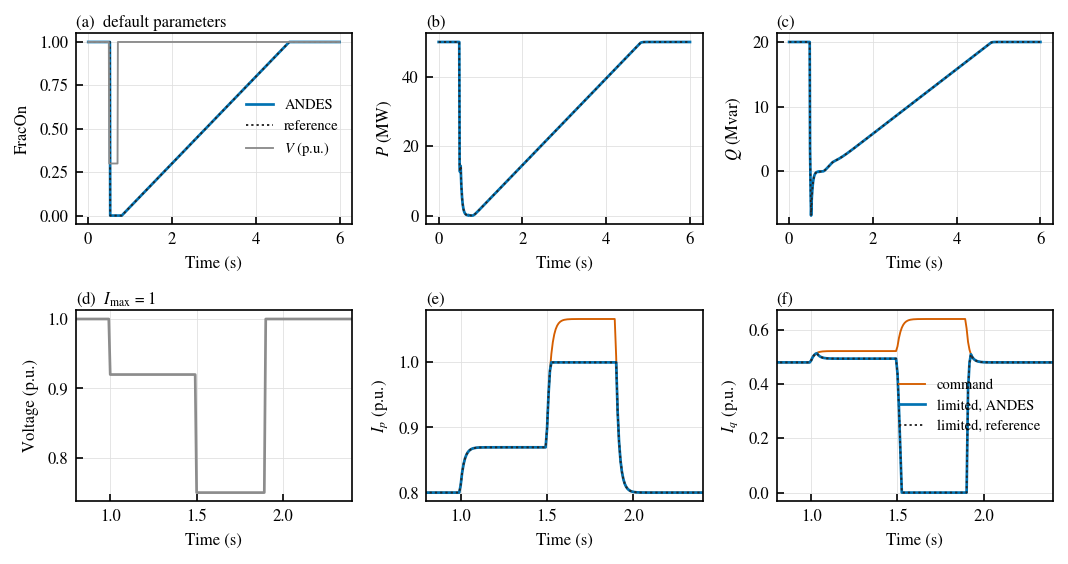

Fig. 2.  Device level. (a)-(c) Default parameters, dip to 0.3 pu for 0.2 s: the cease is raised to a long cease by VLC4, so the load returns with the 4 s ramp TLrampL x Lfm. (d)-(f) Total current limit: at 0.92 pu Iq is cut to the current left by Ip, at 0.75 pu Ip takes all of Imax.


In [12]:
# Fig. 2: default parameters and the Imax scenario, ANDES and reference
DOT = dict(color=C_INK, lw=0.9, ls=(0, (1.2, 1.6)))
fig, axs = plt.subplots(2, 3, figsize=(W2, 3.8))
a, r = RES_B['defaults']
for ax, key, lab, tag in zip(axs[0], ('FracOn', 'Pmw', 'Qmvar'), ('FracOn', '$P$ (MW)', '$Q$ (Mvar)'), 'abc'):
    ax.plot(a['t'], a[key], color=C_BLUE, label='ANDES')
    ax.plot(a['t'], r[key], label='reference', **DOT)
    ax.set_ylabel(lab)
    panel(ax, tag, 'default parameters' if tag == 'a' else '')
axs[0, 0].plot(a['t'], a['V'], color=C_GREY, lw=0.9, label='$V$ (p.u.)')
axs[0, 0].legend(loc='center right')
a, r = RES_B['Imax']
axs[1, 0].plot(a['t'], a['V'], color=C_GREY)
axs[1, 0].set_ylabel('Voltage (p.u.)')
panel(axs[1, 0], 'd', '$I_\\mathrm{max}$ = 1')
for ax, cmd, lim, lab, tag in (
    (axs[1, 1], 'Ipcmd', 'Ipv', '$I_p$ (p.u.)', 'e'),
    (axs[1, 2], 'Iqcmd', 'Iqv', '$I_q$ (p.u.)', 'f'),
):
    ax.plot(a['t'], a[cmd], color=C_ORANGE, lw=0.9, label='command')
    ax.plot(a['t'], a[lim], color=C_BLUE, label='limited, ANDES')
    ax.plot(a['t'], r[lim], label='limited, reference', **DOT)
    ax.set_ylabel(lab)
    panel(ax, tag)
axs[1, 2].legend(loc='center right')
for ax in axs[1]:
    ax.set_xlim(0.8, 2.4)
for ax in axs.ravel():
    ax.set_xlabel('Time (s)')
plt.tight_layout()
plt.show()
print('Fig. 2.  Device level. (a)-(c) Default parameters, dip to 0.3 pu for 0.2 s: the cease is raised to a long '
      'cease by VLC4, so the load returns with the 4 s ramp TLrampL x Lfm. (d)-(f) Total current limit: at 0.92 pu '
      'Iq is cut to the current left by Ip, at 0.75 pu Ip takes all of Imax.')

## 4 Test C: IEEE 14-bus system

The case files are the ANDES case `ieee14_full.xlsx` with the 20 MW, 7 Mvar load at bus 14 modeled by PERC2, with the parameters of Test A.

- `ieee14_perc2_fault.xlsx`: three-phase faults at bus 9 during 1.00–1.25 s and 3.50–3.55 s.
- `ieee14_perc2_gentrip.xlsx`: the generator at bus 2 (40 MW) trips at 1.0 s; `FLC1` = 59.72 Hz and `TFLC1` = 1.0 s.

In [13]:
def run_ieee14(case, tf, trip=False):
    """Run an IEEE 14-bus case with the PERC2 data center at bus 14."""
    ss = andes.load(str(case), setup=False, no_output=True, default_config=True)
    ss.setup()
    ss.PFlow.config.tol = 1e-10
    ss.PFlow.run()
    ss.TDS.config.tstep, ss.TDS.config.tf, ss.TDS.config.tol, ss.TDS.config.no_tqdm = 1 / 120, tf, 1e-6, 1
    ss.TDS.config.criteria = 0 if trip else 1  # a tripped machine drifts away: no angle criterion
    ss.TDS.run(no_summary=True)
    ss.dae.ts.unpack()
    return ss


def rec(ss, var, j=0):
    """Recorded time series of a variable of device j."""
    arr = ss.dae.ts.x if var.v_code == 'x' else ss.dae.ts.y
    return np.array(arr[:, var.a[j]])


def replay(ss):
    """The pseudo-code on the recorded (t, Vfilt, Ffilt); True if it reproduces all recorded logic outputs."""
    m, t = ss.PERC2, np.array(ss.dae.ts.t)
    logic = CeaseLogic2({k: m.__dict__[k].v[0] for k in list(PRM) + list(FLAGS)})
    vf, ff = rec(ss, m.Vfilt), FN * (1 + rec(ss, m.wfilt))
    S = np.zeros((len(t), 8))
    for i in range(len(t)):
        logic.step(t[i], vf[i], ff[i])
        S[i] = logic.state()
    got = np.column_stack([rec(ss, m.__dict__[k]) for k in LOGIC_OUT])
    return np.array_equal(S[:, :6], got) and np.abs(S[:, 7] - rec(ss, m.FracOn)).max() < 1e-12


sf = run_ieee14(CASE_FAULT, 5.5)
t, m = np.array(sf.dae.ts.t), sf.PERC2
sig = {k: rec(sf, m.__dict__[k]) for k in OUTPUTS}
P0, Q0 = sf.PQ.Ppf.v[sf.PQ.idx2uid(m.pq.v[0])] * SB, sf.PQ.Qpf.v[sf.PQ.idx2uid(m.pq.v[0])] * SB
check(
    'C1',
    'IEEE-14 initialization: the PQ load at bus 14 is taken over at its power-flow value',
    sf.TDS.test_ok and abs(sig['Pmw'][0] - P0) < 1e-6 and abs(sig['Qmvar'][0] - Q0) < 1e-6,
    f"P = {sig['Pmw'][0]:.3f} MW, Q = {sig['Qmvar'][0]:.3f} Mvar, V0 = {m.v0.v[0]:.4f} pu",
)

# C2: events of the fault case
k_mode = np.flatnonzero(np.diff(sig['Mode'])) + 1
k_up = np.flatnonzero(np.diff(sig['CeaseLevel']) > 0) + 1
t_cease, t_ramp, t_back = t[k_mode]
t_long = t[k_up[1]]  # level 0 -> 1 while ceased
inside = (sig['Vfilt'] >= m.VLrecone.v[0]) & (sig['Vfilt'] <= m.VHrecone.v[0])
t_in = t[np.flatnonzero(~inside & (t < t_ramp))[-1] + 1]  # last entry into the reconnection window
vl_timer = (sig['Tact'].astype(int) >> TIMERS.index('VLcease')) & 1
second = (t > 3.5) & (t < 3.6)
print(f'cease {t_cease:.3f} s (level 0), raised to level 1 at {t_long:.3f} s, Vfilt peak {sig["Vfilt"].max():.3f} pu, '
      f'window entered at {t_in:.3f} s, ramp {t_ramp:.3f}-{t_back:.3f} s')
check(
    'C2',
    'fault: cease, raised to a long cease, return through the voltage window with the long ramp',
    sf.exit_code == 0
    and t_cease < 1.25
    and sig['CeaseLevel'][k_mode[0]] == 0
    and t_cease < t_long < 1.25
    and sig['Vfilt'].max() > m.VHrecone.v[0]
    and abs(t_ramp - t_in - PRM['TLreconL']) < 2 / 120
    and abs(t_back - t_ramp - PRM['TLrampL'] * PRM['Lfm']) < 2 / 120
    and vl_timer[second].max() == 1
    and np.all(sig['Mode'][second] == RAMP)
    and abs(sig['FracOn'][-1] - F_FINAL) < 1e-12,
    f'raised by VLC4 while ceased; reconnection delay {sig["TreconUsed"][k_mode[1] - 1]:g} s counted from the entry '
    f'into the window; ramp {t_back - t_ramp:.2f} s = TLrampL x Lfm; the 3-cycle fault during the ramp does not '
    f'cease the load; final FracOn {sig["FracOn"][-1]:.2f}',
)
check(
    'C3',
    'pseudo-code replayed on the recorded Vfilt and Ffilt reproduces all logic outputs (fault case)',
    replay(sf),
    f'{len(t)} accepted steps',
)

[PASS] C1   IEEE-14 initialization: the PQ load at bus 14 is taken over at its power-flow value
            P = 20.000 MW, Q = 7.000 Mvar, V0 = 1.0163 pu
cease 1.158 s (level 0), raised to level 1 at 1.191 s, Vfilt peak 1.122 pu, window entered at 1.858 s, ramp 2.366-4.367 s
[PASS] C2   fault: cease, raised to a long cease, return through the voltage window with the long ramp
            raised by VLC4 while ceased; reconnection delay 0.5 s counted from the entry into the window; ramp 2.00 s = TLrampL x Lfm; the 3-cycle fault during the ramp does not cease the load; final FracOn 0.70
[PASS] C3   pseudo-code replayed on the recorded Vfilt and Ffilt reproduces all logic outputs (fault case)
            672 accepted steps


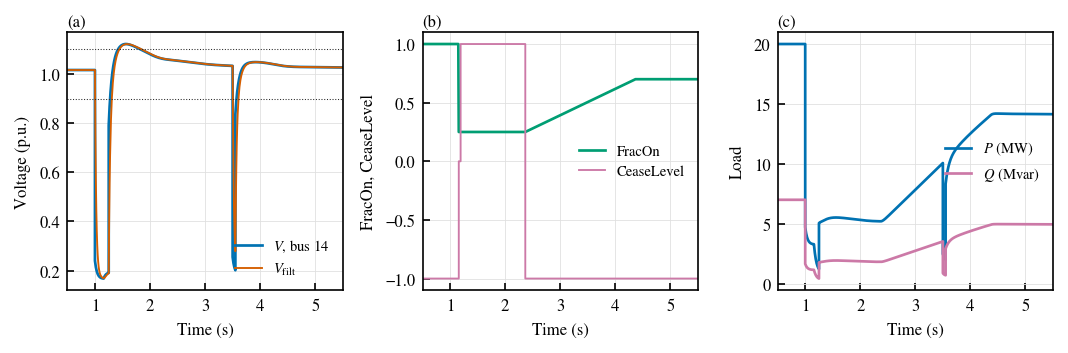

Fig. 3.  IEEE 14-bus system, faults at bus 9 (1.00-1.25 s and 3.50-3.55 s). (a) Bus and model voltage; dotted: reconnection window. (b) FracOn and CeaseLevel. (c) Load power.


In [14]:
# Fig. 3: fault at bus 9
fig, axs = plt.subplots(1, 3, figsize=(W2, 2.4))
ax = axs[0]
ax.plot(t, rec(sf, sf.Bus.v, sf.Bus.idx2uid(m.bus.v[0])), color=C_BLUE, label='$V$, bus 14')
ax.plot(t, sig['Vfilt'], color=C_ORANGE, lw=0.9, label='$V_\\mathrm{filt}$')
for lvl in (m.VLrecone.v[0], m.VHrecone.v[0]):
    ax.axhline(lvl, color=C_INK, lw=0.5, ls=':')
ax.set_ylabel('Voltage (p.u.)')
ax.legend(loc='lower right')
ax = axs[1]
ax.plot(t, sig['FracOn'], color=C_GREEN, label='FracOn')
ax.step(t, sig['CeaseLevel'], where='post', color=C_MAG, lw=0.9, label='CeaseLevel')
ax.set_ylabel('FracOn, CeaseLevel')
ax.legend(loc='center right')
ax = axs[2]
ax.plot(t, sig['Pmw'], color=C_BLUE, label='$P$ (MW)')
ax.plot(t, sig['Qmvar'], color=C_MAG, label='$Q$ (Mvar)')
ax.set_ylabel('Load')
ax.legend(loc='center right')
for ax, tag in zip(axs, 'abc'):
    ax.set_xlabel('Time (s)')
    ax.set_xlim(0.5, 5.5)
    panel(ax, tag)
plt.tight_layout()
plt.show()
print('Fig. 3.  IEEE 14-bus system, faults at bus 9 (1.00-1.25 s and 3.50-3.55 s). (a) Bus and model voltage; '
      'dotted: reconnection window. (b) FracOn and CeaseLevel. (c) Load power.')

[PASS] C4   generator trip: Ffilt < FLC1 for TFLC1 -> CeaseLevel 2; no reconnection although the frequency recovers
            Ffilt < 59.72 Hz from 3.18 s, cease at 4.23 s; at 12 s Ffilt = 59.84 Hz, FracOn = 0.25
[PASS] C5   pseudo-code replayed on the recorded Vfilt and Ffilt reproduces all logic outputs (trip case)
            1443 accepted steps


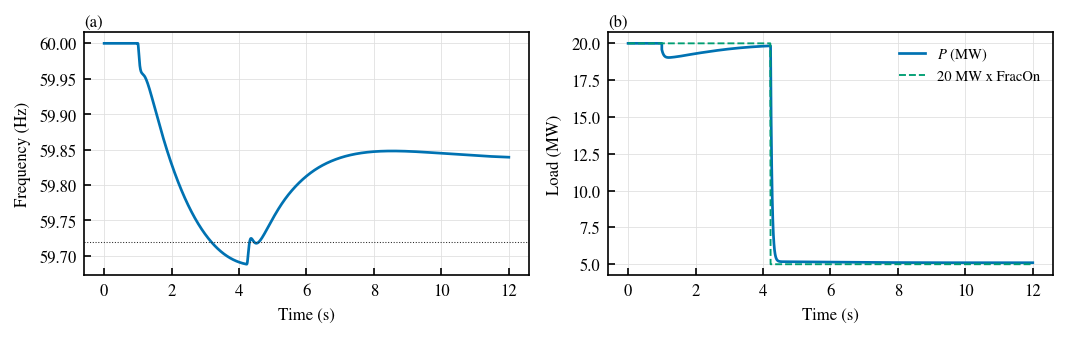

Fig. 4.  IEEE 14-bus system, trip of the generator at bus 2 (40 MW) at 1.0 s. (a) Filtered frequency of the model; dotted: FLC1. (b) Load power: 75 % of the data center ceases and does not return.


In [15]:
# C4: generator trip. FLC1 = 59.72 Hz, TFLC1 = 1 s: the frequency zone ceases the load for good.
sg = run_ieee14(CASE_TRIP, 12.0, trip=True)
tg, mg = np.array(sg.dae.ts.t), sg.PERC2
g = {k: rec(sg, mg.__dict__[k]) for k in OUTPUTS}
ffilt = FN * (1 + g['wfilt'])
kc = np.flatnonzero(np.diff(g['Mode'])) + 1
low = ffilt < mg.FLC1.v[0]
t_low = tg[np.flatnonzero(low)[0]]
inside = (g['Vfilt'] >= mg.VLrecone.v[0]) & (g['Vfilt'] <= mg.VHrecone.v[0])
check(
    'C4',
    'generator trip: Ffilt < FLC1 for TFLC1 -> CeaseLevel 2; no reconnection although the frequency recovers',
    sg.exit_code == 0
    and len(kc) == 1
    and g['CeaseLevel'][-1] == 2
    and g['TreconUsed'][-1] == -1
    and abs(tg[kc[0]] - t_low - mg.TFLC1.v[0] - mg.Tdelay.v[0]) < 2 / 120
    and g['FracOn'][-1] == F_CEASED
    and ffilt[-1] > mg.FLC1.v[0]
    and inside[-1],
    f'Ffilt < {mg.FLC1.v[0]:g} Hz from {t_low:.2f} s, cease at {tg[kc[0]]:.2f} s; at 12 s Ffilt = {ffilt[-1]:.2f} Hz, '
    f'FracOn = {g["FracOn"][-1]:.2f}',
)
check(
    'C5',
    'pseudo-code replayed on the recorded Vfilt and Ffilt reproduces all logic outputs (trip case)',
    replay(sg),
    f'{len(tg)} accepted steps',
)

# Fig. 4
fig, axs = plt.subplots(1, 2, figsize=(W2, 2.3))
axs[0].plot(tg, ffilt, color=C_BLUE, label='$F_\\mathrm{filt}$')
axs[0].axhline(mg.FLC1.v[0], color=C_INK, lw=0.5, ls=':')
axs[0].set_ylabel('Frequency (Hz)')
axs[1].plot(tg, g['Pmw'], color=C_BLUE, label='$P$ (MW)')
axs[1].plot(tg, 20 * g['FracOn'], color=C_GREEN, lw=0.9, ls='--', label='20 MW x FracOn')
axs[1].set_ylabel('Load (MW)')
axs[1].legend(loc='upper right')
for ax, tag in zip(axs, 'ab'):
    ax.set_xlabel('Time (s)')
    panel(ax, tag)
plt.tight_layout()
plt.show()
print('Fig. 4.  IEEE 14-bus system, trip of the generator at bus 2 (40 MW) at 1.0 s. (a) Filtered frequency of the '
      'model; dotted: FLC1. (b) Load power: 75 % of the data center ceases and does not return.')

## 5 Summary

In [16]:
CK = pd.DataFrame(CHECKS)
for row in CK.itertuples():
    print(f"{row.id:<4} {'PASS' if row.passed else 'FAIL'}  {row.description}")
print(f'\n{int(CK.passed.sum())} of {len(CK)} checks passed')
assert CK.passed.all()

A1   PASS  FracOn example: TrampUsed = Tramp x Lfm
A2   PASS  high-voltage cease: 1.30 pu > VHcease
A3   PASS  reconnection window: [VLrecon, VHrecon] = [0.90, 1.10]
A4   PASS  long low voltage: 0.85 pu for 3 s (VLC1 0.90 / 2 s)
A5   PASS  level raised while ceased: 0.70 pu for 1.5 s (VLC2 0.80 / 1 s)
A6   PASS  long high voltage: 1.15 pu for 2 s (VHC1 1.10 / 1 s)
A7   PASS  low frequency: 58.5 Hz for 1 s (FLC1 59 Hz / 0.5 s), never reconnects
A8   PASS  frequency while ceased: level 0 raised to never reconnect
A9   PASS  dip during the ramp: FracOn frozen during Tdelay, then ceased again
A10  PASS  ramp duration = Tramp x Lfm for Lfm = 0.4 / 0.8 / 1.0
A11  PASS  a zone whose flag is 0 does not cease the load
A12  PASS  data modifications at the start: model function equal to the documented rules
A13  PASS  200 random parameter sets and profiles: model function equals the reference at every step
B1   PASS  initialization: P, Q = power-flow load; MBase = P0 / Lfm; Iqextra; window; Tramp